In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from metaflow import Flow, namespace
from sklearn.metrics import ConfusionMatrixDisplay

## Load runs from the AI Orchestration Platform

The notebook server must use the platform's S3 datastore and metadata service (see the README for the `dev3.14` command). The Metaflow client lists runs under `ChurnFlow`; filter by project and production-branch tags to exclude other runs.

In [8]:
namespace(None)
runs = [
    run for run in Flow('ChurnFlow').runs('project:churn_workshop', 'project_branch:prod')
    if run.successful
]
if not runs:
    raise RuntimeError('No successful production runs. Deploy and trigger the flow first.')
print(f'{len(runs)} successful AIO runs')
run = runs[0]
print(f'Inspecting ChurnFlow/{run.id} from {run.created_at}')

5 successful AIO runs
Inspecting ChurnFlow/argo-churnworkshop.prod.churnflow-8sxgc from 2026-09-24 13:34:04.970000


In [4]:
pipeline = run['train'].task.data.pipeline
display(pipeline)
print('Numeric features:', run['train'].task.data.numeric_cols)
print('Categorical features:', run['train'].task.data.categorical_cols)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

Numeric features: ['tenure_months', 'monthly_charges', 'total_charges', 'support_tickets', 'avg_session_minutes']
Categorical features: ['contract_type']


## Results and Cards

The `evaluate` task stores these artifacts on the platform. Open this run's **Cards** tab in Outerbounds and select the `evaluate` task for the `summary` and `interactive_monitoring` Cards. The second Card embeds the deployed Panel app for this exact run.

,score
accuracy,0.812
precision,0.794
recall,0.489
f1,0.605
roc_auc,0.839


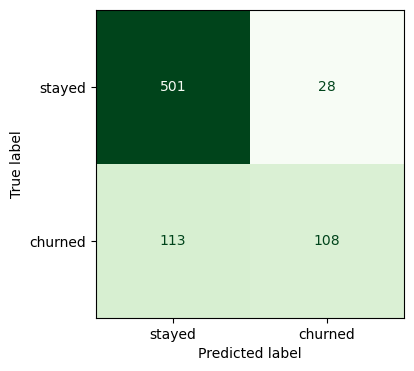

,customer_id,contract_type,y_true,y_pred,churn_probability,scored_week
0,CUST-101801,one-year,0,0,0.320,2026-01-05
1,CUST-101190,one-year,1,1,0.680,2026-01-12
2,CUST-101817,one-year,0,0,0.025,2026-01-19
3,CUST-100251,one-year,0,0,0.220,2026-01-26
4,CUST-102505,one-year,0,0,0.060,2026-02-02


,feature,importance
0,num__total_charges,0.262963
1,num__avg_session_minutes,0.252947
2,num__tenure_months,0.170206
3,num__monthly_charges,0.160415
4,num__support_tickets,0.072409
5,cat__contract_type_month-to-month,0.046485
6,cat__contract_type_one-year,0.019304
7,cat__contract_type_two-year,0.015271


In [10]:
result = run['evaluate'].task.data
display(pd.Series(result.metrics, name='score').to_frame().round(3))
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(np.asarray(result.confusion), display_labels=['stayed', 'churned']).plot(
    ax=ax, cmap='Greens', colorbar=False
)
plt.show()
display(result.predictions.head())
display(result.feature_importance.head(8))

,accuracy,precision,recall,f1,roc_auc
argo-churnworkshop.prod.churnflow-8sxgc (200 trees),0.812,0.794,0.489,0.605,0.839
argo-churnworkshop.prod.churnflow-pjrv6 (400 trees),0.811,0.802,0.475,0.597,0.839
argo-churnworkshop.prod.churnflow-747j5 (100 trees),0.805,0.778,0.475,0.590,0.838
argo-churnworkshop.prod.churnflow-gvs5j (50 trees),0.808,0.794,0.471,0.591,0.838
argo-churnworkshop.prod.churnflow-cbjr6 (200 trees),0.812,0.794,0.489,0.605,0.839


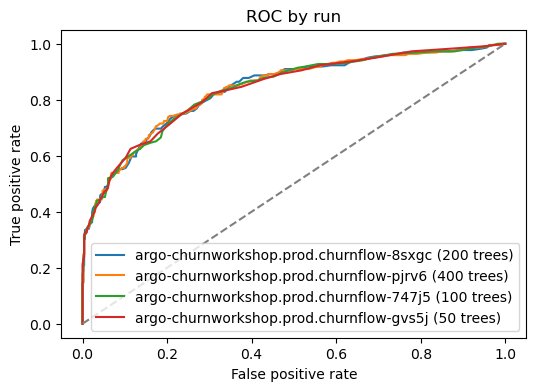

In [11]:
comparison = pd.DataFrame(
    {f'{r.id} ({r.data.n_estimators} trees)': r.data.metrics for r in runs[:6]}
).T
display(comparison.round(3))
fig, ax = plt.subplots(figsize=(6, 4))
for r in runs[:4]:
    curve = r.data.roc_data
    ax.plot(curve.fpr, curve.tpr, label=f'{r.id} ({r.data.n_estimators} trees)')
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC by run')
ax.legend()
plt.show()

## Continue in the AI Orchestration Platform

Inspect the project run graph, each step's logs and persisted artifacts, and the `evaluate` task's Cards. For a comparison, trigger the template again with a different `n-estimators` parameter. `05_card_app.py` is also deployed alongside the flow and can be opened directly. The local `01_wrapped.py` and `02_interactive.py` demos still use the pre-generated files in `artifacts/`; this notebook no longer refreshes them.